# Synthetic spectra generation

Sample M-dwarf stellar parameters from empirical distributions, synthesize spectra across four diagnostically motivated spectral windows (positive control 8800–8835 Å, Ca II IRT 8640–8710 Å, TiO molecular bands 8160–8225 Å, and K I + TiO 7640–7725 Å) at CARMENES VIS resolution (R = 94 600) using Korg, and persist each window as a separate Parquet file for downstream model training.

## Setup

In [ ]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in str(get_ipython())

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_ROOT = Path("/content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars")

    import subprocess
    subprocess.run(
        ["pip", "install", "-q", "juliacall==0.9.27", "juliapkg==0.1.18"],
        check=True,
    )
else:
    REPO_ROOT = Path.cwd().parents[1]

sys.path.insert(0, str(REPO_ROOT))
print("REPO_ROOT:", REPO_ROOT)

from src.datagen import install_korg
install_korg()

Mounted at /content/drive
REPO_ROOT: /content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars
[juliapkg] Found dependencies: /usr/local/lib/python3.12/dist-packages/juliacall/juliapkg.json
[juliapkg] Found dependencies: /usr/local/lib/python3.12/dist-packages/juliapkg/juliapkg.json
[juliapkg] Found dependencies: /root/.julia/environments/pyjuliapkg/pyjuliapkg/juliapkg.json
[juliapkg] Locating Julia ~1.10.3
[juliapkg] WARNING: You have Julia 1.12.6 installed but ~1.10.3 is required.
[juliapkg]   It is recommended that you upgrade Julia or install JuliaUp.
[juliapkg] Querying Julia versions from https://julialang-s3.julialang.org/bin/versions.json
[juliapkg] WARNING: About to install Julia 1.10.11 to /root/.julia/environments/pyjuliapkg/pyjuliapkg/install.
[juliapkg]   If you use juliapkg in more than one environment, you are likely to
[juliapkg]   have Julia installed in multiple locations. It is recommended to
[juliapkg]   install JuliaUp (https://github.com/JuliaLang/juliaup) or

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import src.datavis as datavis
from src.datagen import (
    generate_synthetic_spectra_dataset,
    synthesize_spectra_from_stars,
    _load_korg,
)
from src.dataset import _save_spectra_parquet

2026-05-04 11:08:19.086432: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-05-04 11:08:19.336714: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


M-dwarf physical ranges. Teff range source: https://www.pas.rochester.edu/~emamajek/EEM_dwarf_UBVIJHK_colors_Teff.txt

In [ ]:
EFFECTIVE_TEMP_RANGE_K = (2350.0, 3850.0)  # Teff in Kelvin
METALLICITY_FEH_RANGE = (-0.5, 0.5)  # [Fe/H] in dex
MASS_RANGE_MSUN = (0.079, 0.57)  # stellar mass in M_sun, M0 V to M7 V

NUM_SAMPLES = 5000

## Generate data

In [ ]:
stars = generate_synthetic_spectra_dataset(
    num_samples=NUM_SAMPLES,
    teff_range_K=EFFECTIVE_TEMP_RANGE_K,
    feh_range_dex=METALLICITY_FEH_RANGE,
    mass_range_msun=MASS_RANGE_MSUN,
    synthesize = False,
)

df_stars = pd.DataFrame(stars)
df_stars.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun
0,3254.956173,4.939098,-0.183895,0.198350,0.249843
1,2913.983554,5.328841,-0.031477,0.124337,0.126293
2,2801.829081,5.278537,-0.100134,0.151975,0.147951
3,3651.813996,5.192174,-0.038078,0.202829,0.188790
4,3211.370999,5.091381,0.017231,0.211826,0.216670


In [ ]:
# Persist the stellar parameter dataset — shared input for all spectral window syntheses.
BASE_PATH = REPO_ROOT / "data"
BASE_PATH.mkdir(exist_ok=True)
df_stars.to_parquet(BASE_PATH / "stars.parquet", engine="pyarrow", index=False)

In [ ]:
korg = _load_korg()
BASE_PATH = REPO_ROOT / "data"
BASE_PATH.mkdir(exist_ok=True)

windows = {
    "controle_positivo": (8800.0, 8835.0),
    "triplete_ca_ii":    (8640.0, 8710.0),
    "bandas_tio":        (8160.0, 8225.0),
    "linhas_k_i_tio":   (7640.0, 7725.0),
}

for window_name, window_A in windows.items():
    print(f"\n--- Window: {window_name} {window_A} ---")

    data = synthesize_spectra_from_stars(
        df_stars=df_stars,
        wavelength_window_A=window_A,
        R=94600,
        korg=korg,
    )

    df_spectra = pd.DataFrame(data)
    print(f"Synthesized: {len(df_spectra)}/{len(df_stars)} stars")

    _save_spectra_parquet(
        df_spectra=df_spectra,
        base_path=BASE_PATH,
        filename=f"spectra_{window_name}.parquet",
    )


--- Window: controle_positivo (8800.0, 8835.0) ---


Synthesized: 5000/5000 stars
Wrote /content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars/data/spectra_controle_positivo.parquet

--- Window: triplete_ca_ii (8640.0, 8710.0) ---


Synthesized: 5000/5000 stars
Wrote /content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars/data/spectra_triplete_ca_ii.parquet

--- Window: bandas_tio (8160.0, 8225.0) ---


Synthesized: 5000/5000 stars
Wrote /content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars/data/spectra_bandas_tio.parquet

--- Window: linhas_k_i_tio (7640.0, 7725.0) ---


Synthesized: 5000/5000 stars
Wrote /content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars/data/spectra_linhas_k_i_tio.parquet


## Visualize

### Stars Parameters

In [ ]:
df_stars_check = pd.read_parquet('/content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars/data/stars.parquet')
df_stars_check.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun
0,3254.956173,4.939098,-0.183895,0.198350,0.249843
1,2913.983554,5.328841,-0.031477,0.124337,0.126293
2,2801.829081,5.278537,-0.100134,0.151975,0.147951
3,3651.813996,5.192174,-0.038078,0.202829,0.188790
4,3211.370999,5.091381,0.017231,0.211826,0.216670


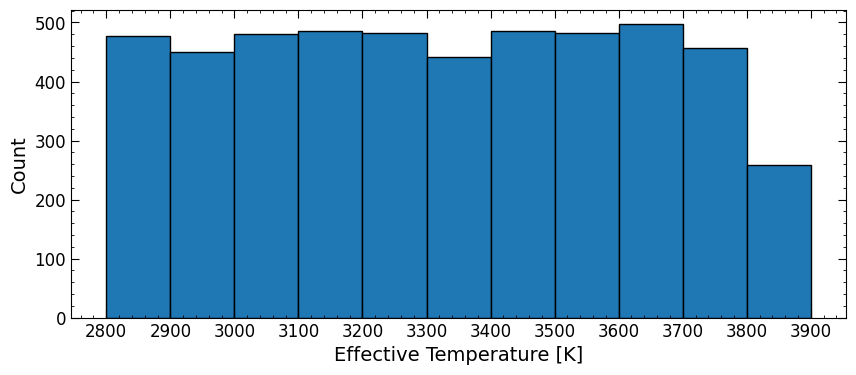

In [ ]:
datavis.plot_histogram(
    df_stars_check, "Teff_K", (2800, 3900), 100, xlabel="Effective Temperature [K]"
    )
plt.show()

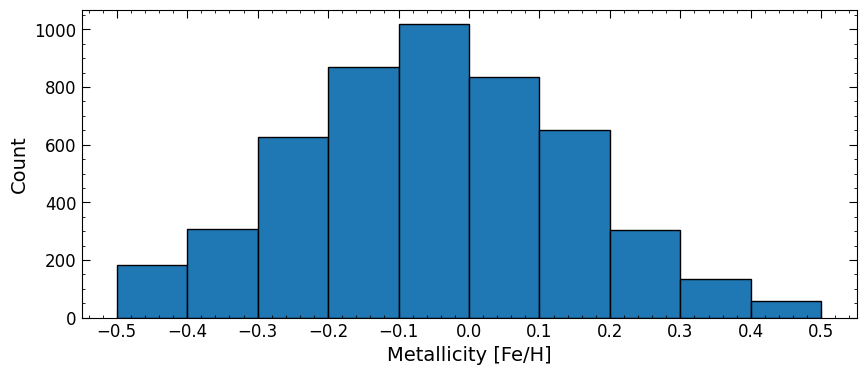

In [ ]:
datavis.plot_histogram(
    df_stars_check, "FeH_dex", METALLICITY_FEH_RANGE, 0.1, xlabel="Metallicity [Fe/H]"
    )
plt.show()

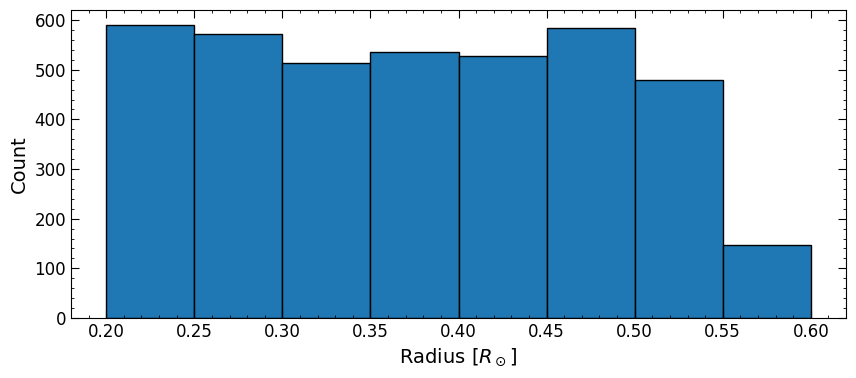

In [ ]:
datavis.plot_histogram(
    df_stars_check, "Radius_Rsun", (0.2, 0.6), 0.05, xlabel=r"Radius [$R_\odot$]"
    )
plt.show()

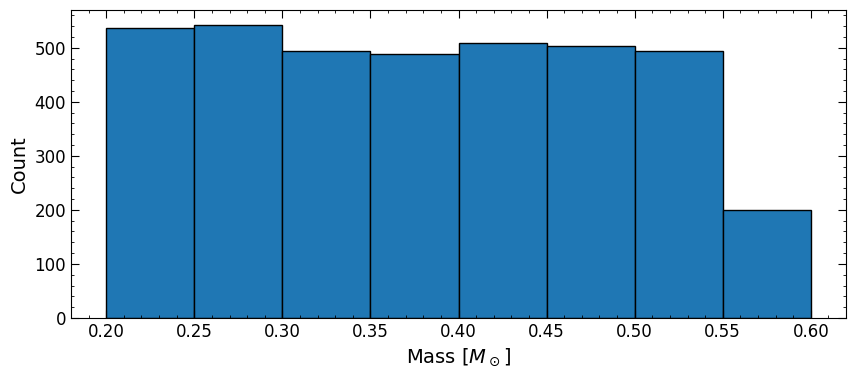

In [ ]:
datavis.plot_histogram(
    df_stars_check, "Mass_Msun", (0.2, 0.6), 0.05, xlabel=r"Mass [$M_\odot$]"
    )
plt.show()

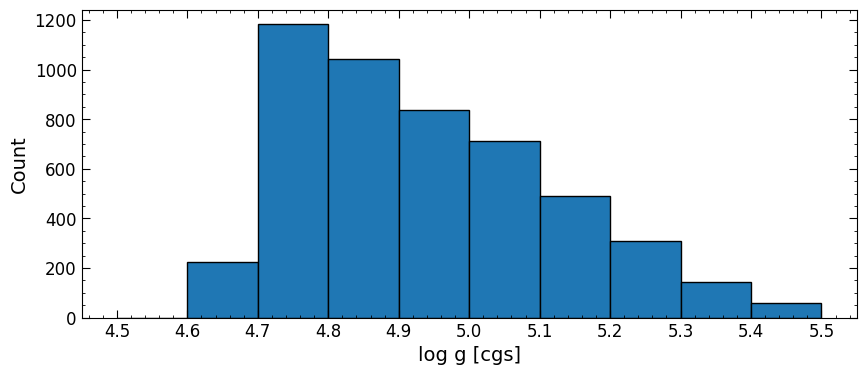

In [ ]:
datavis.plot_histogram(
    df_stars_check, "logg_cgs", (4.5, 5.5), 0.1, xlabel="log g [cgs]"
    )
plt.show()

### Windows

#### Positive Control 8800–8835 Å

In [ ]:
df_positive_control = pd.read_parquet('/content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars/data/spectra_controle_positivo.parquet')
df_positive_control.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3254.956173,4.939098,-0.183895,0.198350,0.249843,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9993249177932739, 0.9993242621421814, 0.999...","[652524.125, 652523.9375, 652523.75, 652523.56..."
1,2913.983554,5.328841,-0.031477,0.124337,0.126293,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9992531538009644, 0.9992526769638062, 0.999...","[500245.5, 500245.5, 500245.5, 500245.5, 50024..."
2,2801.829081,5.278537,-0.100134,0.151975,0.147951,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9993431568145752, 0.9993427991867065, 0.999...","[451051.09375, 451051.125, 451051.1875, 451051..."
3,3651.813996,5.192174,-0.038078,0.202829,0.188790,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9983136653900146, 0.9983119964599609, 0.998...","[994164.8125, 994164.0625, 994163.3125, 994162..."
4,3211.370999,5.091381,0.017231,0.211826,0.216670,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.99918532371521, 0.9991846680641174, 0.99918...","[650864.375, 650864.1875, 650864.0, 650863.812..."


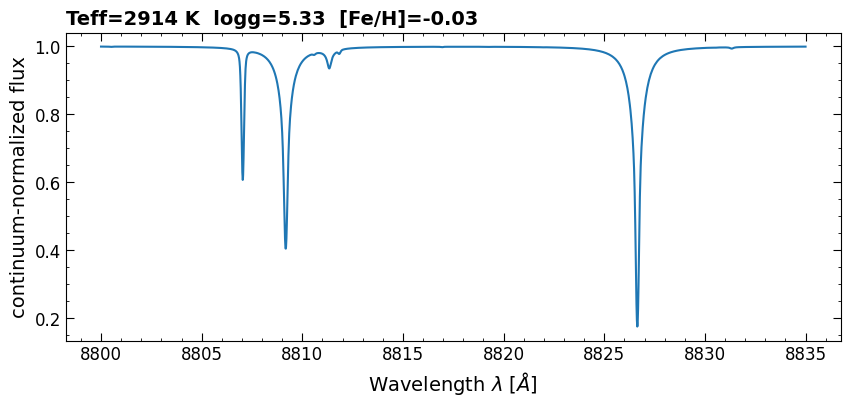

In [ ]:
datavis.plot_single_spectrum(df_positive_control, row_index=1)
plt.show()

### Ca II IRT 8640–8710 Å

In [ ]:
df_Ca_II_IRT = pd.read_parquet('/content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars/data/spectra_triplete_ca_ii.parquet')
df_Ca_II_IRT.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3254.956173,4.939098,-0.183895,0.198350,0.249843,"[8640.0, 8640.009765625, 8640.01953125, 8640.0...","[0.999076783657074, 0.999076783657074, 0.99907...","[655244.9375, 655244.8125, 655244.625, 655244...."
1,2913.983554,5.328841,-0.031477,0.124337,0.126293,"[8640.0, 8640.009765625, 8640.01953125, 8640.0...","[0.999534010887146, 0.9995343089103699, 0.9995...","[499997.53125, 499997.5625, 499997.625, 499997..."
2,2801.829081,5.278537,-0.100134,0.151975,0.147951,"[8640.0, 8640.009765625, 8640.01953125, 8640.0...","[0.9996241331100464, 0.9996243715286255, 0.999...","[450003.78125, 450003.875, 450003.96875, 45000..."
3,3651.813996,5.192174,-0.038078,0.202829,0.188790,"[8640.0, 8640.009765625, 8640.01953125, 8640.0...","[0.9980466365814209, 0.998047411441803, 0.9980...","[1005700.4375, 1005699.6875, 1005699.0, 100569..."
4,3211.370999,5.091381,0.017231,0.211826,0.216670,"[8640.0, 8640.009765625, 8640.01953125, 8640.0...","[0.9990870356559753, 0.9990873336791992, 0.999...","[653555.8125, 653555.625, 653555.5, 653555.375..."


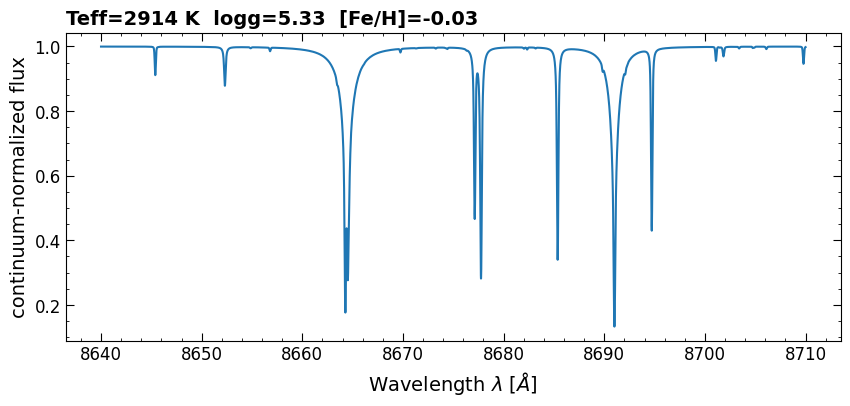

In [ ]:
datavis.plot_single_spectrum(df_Ca_II_IRT, row_index=1)
plt.show()

### TiO molecular bands 8160–8225 Å

In [ ]:
df_TiO_molecular_bands = pd.read_parquet('/content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars/data/spectra_bandas_tio.parquet')
df_TiO_molecular_bands.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3254.956173,4.939098,-0.183895,0.198350,0.249843,"[8160.0, 8160.009765625, 8160.02001953125, 816...","[0.9973495602607727, 0.9973487854003906, 0.997...","[658589.0, 658589.0, 658589.0625, 658589.0625,..."
1,2913.983554,5.328841,-0.031477,0.124337,0.126293,"[8160.0, 8160.009765625, 8160.02001953125, 816...","[0.9878250360488892, 0.987821638584137, 0.9878...","[495072.1875, 495072.375, 495072.5625, 495072...."
2,2801.829081,5.278537,-0.100134,0.151975,0.147951,"[8160.0, 8160.009765625, 8160.02001953125, 816...","[0.9862304925918579, 0.9862266778945923, 0.986...","[442953.40625, 442953.625, 442953.84375, 44295..."
3,3651.813996,5.192174,-0.038078,0.202829,0.188790,"[8160.0, 8160.009765625, 8160.02001953125, 816...","[0.9984288811683655, 0.9984282851219177, 0.998...","[1035370.0, 1035369.4375, 1035368.9375, 103536..."
4,3211.370999,5.091381,0.017231,0.211826,0.216670,"[8160.0, 8160.009765625, 8160.02001953125, 816...","[0.9957497119903564, 0.9957485198974609, 0.995...","[656827.125, 656827.1875, 656827.1875, 656827...."


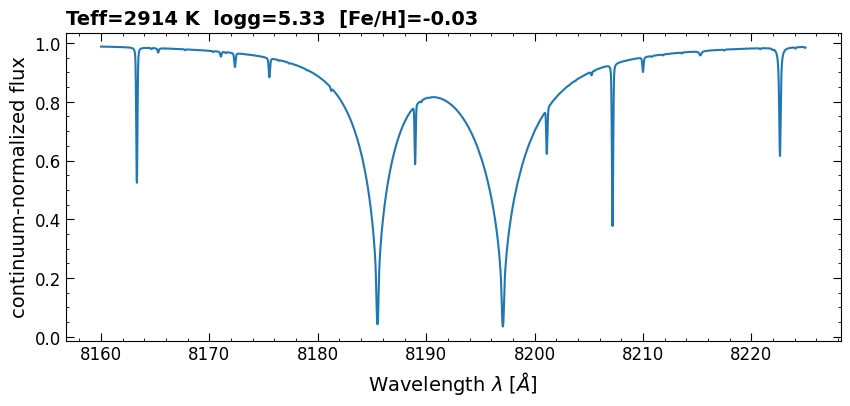

In [ ]:
datavis.plot_single_spectrum(df_TiO_molecular_bands, row_index=1)
plt.show()

### K I + TiO 7640–7725 Å

In [ ]:
df_K_I_TiO = pd.read_parquet('/content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars/data/spectra_linhas_k_i_tio.parquet')
df_K_I_TiO.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3254.956173,4.939098,-0.183895,0.198350,0.249843,"[7640.0, 7640.009765625, 7640.02001953125, 764...","[0.9962224960327148, 0.9962213635444641, 0.996...","[651918.75, 651919.0, 651919.3125, 651919.5625..."
1,2913.983554,5.328841,-0.031477,0.124337,0.126293,"[7640.0, 7640.009765625, 7640.02001953125, 764...","[0.9559702277183533, 0.9559577107429504, 0.955...","[481146.78125, 481147.15625, 481147.53125, 481..."
2,2801.829081,5.278537,-0.100134,0.151975,0.147951,"[7640.0, 7640.009765625, 7640.02001953125, 764...","[0.9324816465377808, 0.9324631690979004, 0.932...","[427399.84375, 427400.21875, 427400.625, 42740..."
3,3651.813996,5.192174,-0.038078,0.202829,0.188790,"[7640.0, 7640.009765625, 7640.02001953125, 764...","[0.9986835718154907, 0.9986830949783325, 0.998...","[1055717.25, 1055717.125, 1055716.875, 1055716..."
4,3211.370999,5.091381,0.017231,0.211826,0.216670,"[7640.0, 7640.009765625, 7640.02001953125, 764...","[0.9934037327766418, 0.9934002161026001, 0.993...","[650094.9375, 650095.1875, 650095.4375, 650095..."


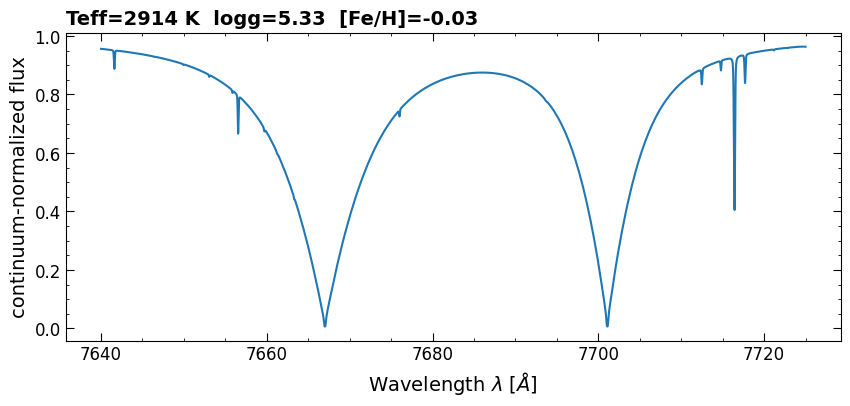

In [ ]:
datavis.plot_single_spectrum(df_K_I_TiO, row_index=1)
plt.show()